# CitizenTech — Vai chover na próxima hora em São Paulo?

**Integrantes:** Albert Katri (RM556544), Bruno Biletsky (RM554739) e Paulo Akira (RM556840)

## 1. Problema e pergunta de Machine Learning

Chuvas repentinas em São Paulo afetam diretamente o cidadão: alagamentos, trânsito, atraso no transporte público e risco para quem está na rua. A CitizenTech quer oferecer um **aviso de curtíssimo prazo** que ajude a pessoa a decidir se sai agora, leva guarda-chuva ou espera.

**Pergunta de ML (classificação binária):** *com as medições da estação meteorológica oficial do INMET na hora atual e nas horas anteriores, é possível prever se vai chover (precipitação ≥ 0,2 mm) na próxima hora em São Paulo?*

- **Alvo:** `chuva_prox_hora` = 1 se a precipitação registrada na hora seguinte for maior que zero (0,2 mm é a resolução do pluviômetro); 0 caso contrário.
- **Dados reais e públicos:** estação automática **INMET A701 — São Paulo/Mirante de Santana**, série horária de **01/01/2023 a 31/12/2025** (arquivos oficiais brutos versionados em `ml/dados/brutos/`; fonte e link em `ml/dados/README.md`). Nenhum dado simulado é usado.
- **Modelo:** Random Forest (justificativa na seção 4), com 18 combinações de 3 hiperparâmetros, validação cruzada temporal somente no treino.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report,
                             ConfusionMatrixDisplay, f1_score, precision_score, recall_score,
                             roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

RANDOM_STATE = 42
DATA_DIR = Path("dados/brutos") if Path("dados/brutos").exists() else Path("ml/dados/brutos")
FIG_DIR = DATA_DIR.parent.parent / "figuras"
FIG_DIR.mkdir(exist_ok=True)
arquivos = sorted(DATA_DIR.glob("INMET_A701_*.CSV"))
print("Arquivos INMET encontrados:")
for f in arquivos:
    print(" -", f.name, f"({f.stat().st_size/1024:.0f} KB)")

Arquivos INMET encontrados:
 - INMET_A701_SAO_PAULO_MIRANTE_2023.CSV (782 KB)
 - INMET_A701_SAO_PAULO_MIRANTE_2024.CSV (793 KB)
 - INMET_A701_SAO_PAULO_MIRANTE_2025.CSV (792 KB)


## 2. Leitura dos dados brutos do INMET

Os arquivos são exatamente os publicados pelo INMET em *Dados Históricos* (um CSV por ano, separador `;`, decimal `,`, codificação Latin-1, 8 linhas de cabeçalho com metadados da estação). O INMET marca falhas do sensor como `-9999` ou célula vazia.

In [2]:
with open(arquivos[0], encoding="latin-1") as f:
    print("".join(f.readline() for _ in range(8)))

RENOMEAR = {
    "PRECIPITAÇÃO TOTAL, HORÁRIO (mm)": "precipitacao_mm",
    "PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)": "pressao_hpa",
    "RADIACAO GLOBAL (Kj/m²)": "radiacao_kj_m2",
    "TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)": "temperatura_c",
    "TEMPERATURA DO PONTO DE ORVALHO (°C)": "ponto_orvalho_c",
    "UMIDADE RELATIVA DO AR, HORARIA (%)": "umidade_pct",
    "VENTO, DIREÇÃO HORARIA (gr) (° (gr))": "vento_direcao_graus",
    "VENTO, RAJADA MAXIMA (m/s)": "vento_rajada_ms",
    "VENTO, VELOCIDADE HORARIA (m/s)": "vento_velocidade_ms",
}

partes = []
for f in arquivos:
    df = pd.read_csv(f, sep=";", skiprows=8, encoding="latin-1", decimal=",",
                     na_values=["-9999", -9999, ""])
    df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
    partes.append(df)
bruto = pd.concat(partes, ignore_index=True)
print("Formato bruto:", bruto.shape)
bruto.head()

REGIAO:;SE
UF:;SP
ESTACAO:;SAO PAULO - MIRANTE
CODIGO (WMO):;A701
LATITUDE:;-23,49638888
LONGITUDE:;-46,61999999
ALTITUDE:;785,64
DATA DE FUNDACAO:;25/07/06

Formato bruto: (26304, 19)


,Data,Hora UTC,"PRECIPITAÇÃO TOTAL, HORÁRIO (mm)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)",PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB),PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB),RADIACAO GLOBAL (Kj/m²),"TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)",TEMPERATURA DO PONTO DE ORVALHO (°C),TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C),TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C),TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C),TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C),UMIDADE REL. MAX. NA HORA ANT. (AUT) (%),UMIDADE REL. MIN. NA HORA ANT. (AUT) (%),"UMIDADE RELATIVA DO AR, HORARIA (%)","VENTO, DIREÇÃO HORARIA (gr) (° (gr))","VENTO, RAJADA MAXIMA (m/s)","VENTO, VELOCIDADE HORARIA (m/s)"
0,2023/01/01,0000 UTC,0.0,927.2,927.2,926.9,NaN,20.3,17.2,20.5,20.2,17.2,17.0,83.0,81.0,83.0,124.0,3.1,0.8
1,2023/01/01,0100 UTC,0.0,927.2,927.2,926.9,NaN,20.2,17.5,20.4,20.1,17.6,17.2,85.0,82.0,84.0,143.0,3.1,1.0
2,2023/01/01,0200 UTC,0.0,927.1,927.3,927.1,NaN,20.6,17.9,20.6,20.2,18.0,17.5,85.0,84.0,85.0,115.0,3.5,1.4
3,2023/01/01,0300 UTC,0.0,926.6,927.1,926.6,NaN,20.4,17.9,20.6,20.3,18.0,17.8,86.0,85.0,86.0,130.0,3.3,1.3
4,2023/01/01,0400 UTC,0.0,925.7,926.6,925.7,NaN,19.8,17.3,20.4,19.8,18.0,17.3,86.0,85.0,86.0,89.0,5.3,0.8


## 3. Limpeza e preparação

Passos aplicados (todos sobre dados reais, nada é inventado):

1. **Tempo:** `Data` + `Hora UTC` → horário de Brasília (`America/Sao_Paulo`), índice horário.
2. **Duplicatas e lacunas:** remoção de timestamps duplicados e reindexação para uma grade horária completa, deixando explícitas as horas sem registro.
3. **Faltantes (`-9999`):** convertidos em `NaN`. Radiação global vazia à noite vira 0 (não há sol). Falhas curtas (até 2 h) das variáveis contínuas são preenchidas com o **último valor válido** (`ffill`), que só usa o passado; falhas maiores são descartadas. A **precipitação nunca é imputada**, porque ela define o alvo.
4. **Faixas físicas:** valores fora de limites plausíveis (umidade 0–100 %, pressão 850–1000 hPa, etc.) viram `NaN`.
5. **Variáveis derivadas (só passado e presente):** chuva acumulada nas últimas 3 e 6 h, tendência de pressão em 3 h, variação de umidade e temperatura em 1 h, déficit de ponto de orvalho, direção do vento em seno/cosseno e hora do dia/mês em seno/cosseno (sazonalidade).
6. **Alvo:** `chuva_prox_hora = precipitacao(t+1) > 0`. Linhas sem alvo ou sem atributos completos são removidas.

In [3]:
clima = bruto[list(RENOMEAR)].rename(columns=RENOMEAR)
hora_utc = pd.to_datetime(bruto["Data"] + " " + bruto["Hora UTC"].str[:4], format="%Y/%m/%d %H%M", utc=True)
clima.index = hora_utc.dt.tz_convert("America/Sao_Paulo").rename("data_hora")
clima = clima.sort_index()

n_dup = clima.index.duplicated().sum()
clima = clima[~clima.index.duplicated(keep="first")]
grade = pd.date_range(clima.index.min(), clima.index.max(), freq="h")
horas_ausentes = len(grade) - len(clima)
clima = clima.reindex(grade)
clima.index.name = "data_hora"

LIMITES = {"temperatura_c": (-5, 45), "ponto_orvalho_c": (-20, 35), "umidade_pct": (0, 100),
           "pressao_hpa": (850, 1000), "vento_velocidade_ms": (0, 40), "vento_rajada_ms": (0, 60),
           "vento_direcao_graus": (0, 360), "precipitacao_mm": (0, 150), "radiacao_kj_m2": (0, 5000)}
fora_faixa = {}
for col, (lo, hi) in LIMITES.items():
    mask = clima[col].notna() & ~clima[col].between(lo, hi)
    fora_faixa[col] = int(mask.sum())
    clima.loc[mask, col] = np.nan

faltantes_antes = clima.isna().mean().mul(100).round(2).rename("% faltante (antes)")
print(f"Período: {clima.index.min()} a {clima.index.max()}  |  {len(clima):,} horas")
print(f"Timestamps duplicados removidos: {n_dup} | horas ausentes no arquivo: {horas_ausentes}")
print("Valores fora da faixa física:", {k: v for k, v in fora_faixa.items() if v})
faltantes_antes.to_frame()

Período: 2022-12-31 21:00:00-03:00 a 2025-12-31 20:00:00-03:00  |  26,304 horas
Timestamps duplicados removidos: 0 | horas ausentes no arquivo: 0
Valores fora da faixa física: {}


,% faltante (antes)
precipitacao_mm,2.71
pressao_hpa,1.06
radiacao_kj_m2,46.82
temperatura_c,1.06
ponto_orvalho_c,1.06
umidade_pct,1.06
vento_direcao_graus,1.06
vento_rajada_ms,1.08
vento_velocidade_ms,1.06


In [4]:
# Radiação: o INMET deixa vazio à noite -> 0 quando as demais leituras da hora existem
noite = clima["radiacao_kj_m2"].isna() & clima["temperatura_c"].notna() & (
    (clima.index.hour >= 19) | (clima.index.hour <= 5))
clima.loc[noite, "radiacao_kj_m2"] = 0.0

CONTINUAS = ["pressao_hpa", "radiacao_kj_m2", "temperatura_c", "ponto_orvalho_c", "umidade_pct",
             "vento_direcao_graus", "vento_rajada_ms", "vento_velocidade_ms"]
clima[CONTINUAS] = clima[CONTINUAS].ffill(limit=2)   # só usa o passado; precipitação NÃO é imputada

df = clima.copy()
# atributos derivados - usam apenas t, t-1, t-3, t-6 (nada do futuro)
df["chuva_lag_1"] = df["precipitacao_mm"].shift(1)
df["chuva_acum_3h"] = df["precipitacao_mm"].rolling(3, min_periods=3).sum()
df["chuva_acum_6h"] = df["precipitacao_mm"].rolling(6, min_periods=6).sum()
df["pressao_tend_3h"] = df["pressao_hpa"] - df["pressao_hpa"].shift(3)
df["umidade_var_1h"] = df["umidade_pct"] - df["umidade_pct"].shift(1)
df["temperatura_var_1h"] = df["temperatura_c"] - df["temperatura_c"].shift(1)
df["deficit_orvalho_c"] = df["temperatura_c"] - df["ponto_orvalho_c"]
rad = np.deg2rad(df["vento_direcao_graus"])
df["vento_dir_sen"], df["vento_dir_cos"] = np.sin(rad), np.cos(rad)
df["hora_sen"] = np.sin(2 * np.pi * df.index.hour / 24)
df["hora_cos"] = np.cos(2 * np.pi * df.index.hour / 24)
df["mes_sen"] = np.sin(2 * np.pi * (df.index.month - 1) / 12)
df["mes_cos"] = np.cos(2 * np.pi * (df.index.month - 1) / 12)

# alvo: chuva na PRÓXIMA hora
prox = df["precipitacao_mm"].shift(-1)
df["chuva_prox_hora"] = np.where(prox.isna(), np.nan, (prox > 0).astype(float))

FEATURES = ["precipitacao_mm", "chuva_lag_1", "chuva_acum_3h", "chuva_acum_6h",
            "temperatura_c", "ponto_orvalho_c", "deficit_orvalho_c", "umidade_pct",
            "umidade_var_1h", "temperatura_var_1h", "pressao_hpa", "pressao_tend_3h",
            "radiacao_kj_m2", "vento_velocidade_ms", "vento_rajada_ms",
            "vento_dir_sen", "vento_dir_cos", "hora_sen", "hora_cos", "mes_sen", "mes_cos"]
TARGET = "chuva_prox_hora"

modelo_df = df[FEATURES + [TARGET]].dropna().copy()
modelo_df[TARGET] = modelo_df[TARGET].astype(int)
print(f"Linhas após limpeza: {len(modelo_df):,} de {len(df):,} ({len(modelo_df)/len(df):.1%} aproveitadas)")
print(f"Atributos: {len(FEATURES)}")
print(f"Horas com chuva na hora seguinte: {modelo_df[TARGET].mean():.2%}  -> classes desbalanceadas")
modelo_df.describe().T.round(2)

Linhas após limpeza: 25,024 de 26,304 (95.1% aproveitadas)
Atributos: 21
Horas com chuva na hora seguinte: 7.42%  -> classes desbalanceadas


,count,mean,std,min,25%,50%,75%,max
precipitacao_mm,25024.0,0.19,1.57,0.0,0.00,0.00,0.00,82.0
chuva_lag_1,25024.0,0.19,1.57,0.0,0.00,0.00,0.00,82.0
chuva_acum_3h,25024.0,0.56,3.30,0.0,0.00,0.00,0.00,123.8
chuva_acum_6h,25024.0,1.12,5.11,0.0,0.00,0.00,0.00,125.4
temperatura_c,25024.0,21.10,4.70,5.8,17.80,20.80,24.10,37.2
ponto_orvalho_c,25024.0,14.21,3.79,-6.9,11.80,14.70,17.20,23.5
deficit_orvalho_c,25024.0,6.90,5.20,0.0,3.10,5.00,9.40,33.2
umidade_pct,25024.0,67.86,17.94,12.0,56.00,73.00,82.00,100.0
umidade_var_1h,25024.0,0.01,5.77,-35.0,-3.00,0.00,2.00,56.0
temperatura_var_1h,25024.0,-0.00,1.21,-11.6,-0.50,-0.10,0.50,6.1


### Análise exploratória rápida

A chuva é um evento raro (≈7 % das horas) e concentrado no verão e no fim da tarde — por isso as variáveis de hora e mês entram no modelo, e por isso **acurácia sozinha não serve como métrica** (um modelo que sempre diz “não chove” acertaria ~93 %).

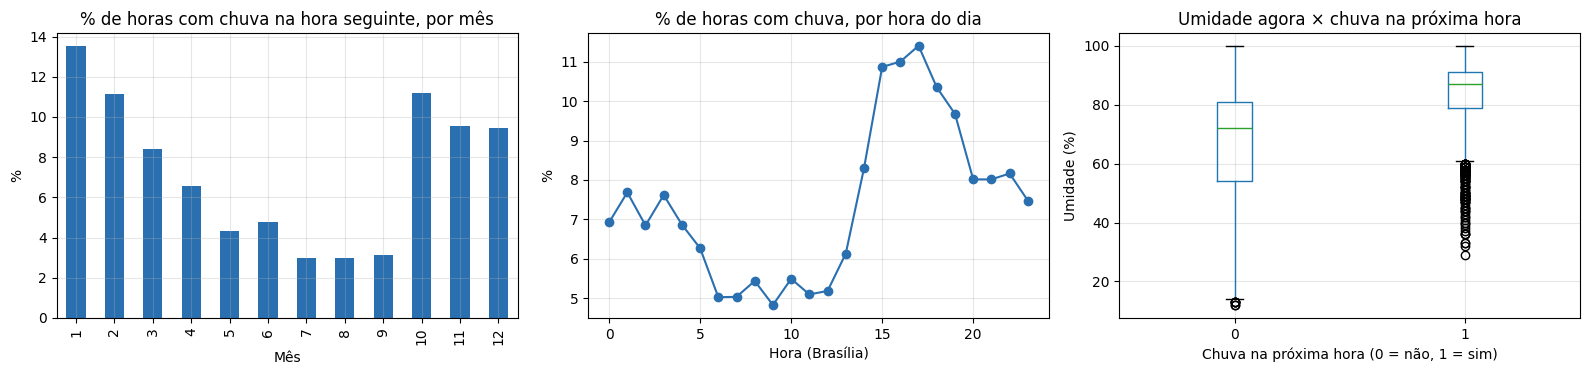

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
mensal = modelo_df.groupby(modelo_df.index.month)[TARGET].mean() * 100
mensal.plot.bar(ax=axes[0], color="#2a6fb0")
axes[0].set(title="% de horas com chuva na hora seguinte, por mês", xlabel="Mês", ylabel="%")
horaria = modelo_df.groupby(modelo_df.index.hour)[TARGET].mean() * 100
horaria.plot(ax=axes[1], marker="o", color="#2a6fb0")
axes[1].set(title="% de horas com chuva, por hora do dia", xlabel="Hora (Brasília)", ylabel="%")
modelo_df.boxplot(column="umidade_pct", by=TARGET, ax=axes[2])
axes[2].set(title="Umidade agora × chuva na próxima hora", xlabel="Chuva na próxima hora (0 = não, 1 = sim)", ylabel="Umidade (%)")
fig.suptitle("")
plt.tight_layout(); plt.show()

### Divisão treino/teste (temporal)

Como é uma série temporal, **não embaralhamos**: o modelo é treinado com o passado e testado no futuro, exatamente como seria usado na prática.

- **Treino:** 2023 e 2024 (2 anos completos, todas as estações do ano).
- **Teste:** 2025 inteiro (1 ano completo, nunca visto durante o treino e a escolha de hiperparâmetros).

Isso evita vazamento de informação do futuro para o passado e garante que o teste cobre verão, inverno e transições.

In [6]:
treino = modelo_df[modelo_df.index.year <= 2024]
teste = modelo_df[modelo_df.index.year == 2025]
X_train, y_train = treino[FEATURES], treino[TARGET]
X_test, y_test = teste[FEATURES], teste[TARGET]

divisao = pd.DataFrame({
    "período": [f"{treino.index.min():%d/%m/%Y} a {treino.index.max():%d/%m/%Y}",
                f"{teste.index.min():%d/%m/%Y} a {teste.index.max():%d/%m/%Y}"],
    "linhas": [len(treino), len(teste)],
    "% do total": [len(treino) / len(modelo_df) * 100, len(teste) / len(modelo_df) * 100],
    "% com chuva": [y_train.mean() * 100, y_test.mean() * 100],
}, index=["Treino", "Teste"]).round(1)
divisao

,período,linhas,% do total,% com chuva
Treino,01/01/2023 a 31/12/2024,16507,66.0,7.9
Teste,01/01/2025 a 31/12/2025,8517,34.0,6.5


## 4. Escolha justificada do modelo: Random Forest

| Critério | Por que Random Forest |
|---|---|
| Dados tabulares com relações não lineares (ex.: umidade alta **e** pressão caindo **e** fim da tarde) | Árvores capturam interações sem precisar criá-las à mão |
| Variáveis em escalas diferentes (hPa, %, kJ/m², m/s) | Não exige normalização |
| Classe rara (~7 %) | `class_weight="balanced"` dá mais peso às horas de chuva |
| Risco de overfitting | Controlado por `max_depth`, `min_samples_leaf` e média de muitas árvores |
| Explicabilidade para o cidadão/gestor | Importância das variáveis mostra *o que* sinaliza a chuva |

Alternativas consideradas: **Regressão Logística** é linear demais para interações meteorológicas; **Naive Bayes** assume independência entre variáveis fortemente correlacionadas (temperatura, orvalho, umidade); **LSTM/MLP** exigiriam mais dados e ajuste, com menor interpretabilidade; **K-means** é não supervisionado e não responde a uma pergunta com rótulo. **XGBoost** seria uma alternativa válida, mas o Random Forest é mais robusto a hiperparâmetros e mais simples de explicar.

### Referências (baselines) para saber se o modelo agrega valor
- **Persistência:** “se está chovendo agora, vai chover na próxima hora” — a regra mais simples que um cidadão usaria.
- **Sempre “não chove”:** mostra por que a acurácia engana.

## 5. Treino com diferentes hiperparâmetros

Grade com **3 hiperparâmetros × 18 combinações** (2 × 3 × 3):

- `n_estimators` ∈ {100, 300} — número de árvores;
- `max_depth` ∈ {6, 12, None} — profundidade máxima (complexidade de cada árvore);
- `min_samples_leaf` ∈ {1, 10, 50} — mínimo de amostras por folha (suavização).

**Validação cruzada somente no treino**, com `TimeSeriesSplit(n_splits=5)`: cada dobra valida em um período posterior ao usado para treinar, respeitando a ordem do tempo. A métrica de seleção é o **F1 da classe “chuva”**, que equilibra alarmes falsos (precisão) e chuvas perdidas (recall). Também registramos PR-AUC e ROC-AUC. O conjunto de teste (2025) **não participa** desta etapa.

In [7]:
param_grid = {
    "n_estimators": [100, 300],
    "max_depth": [6, 12, None],
    "min_samples_leaf": [1, 10, 50],
}
cv = TimeSeriesSplit(n_splits=5)
search = GridSearchCV(
    estimator=RandomForestClassifier(class_weight="balanced", max_features="sqrt",
                                     random_state=RANDOM_STATE, n_jobs=1),
    param_grid=param_grid,
    scoring={"f1": "f1", "pr_auc": "average_precision", "roc_auc": "roc_auc"},
    refit="f1",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)
search.fit(X_train, y_train)

res = pd.DataFrame(search.cv_results_)
tabela_cv = pd.DataFrame({
    "n_estimators": res["param_n_estimators"],
    "max_depth": res["param_max_depth"].astype(str),
    "min_samples_leaf": res["param_min_samples_leaf"],
    "F1 treino (CV)": res["mean_train_f1"],
    "F1 validação (CV)": res["mean_test_f1"],
    "desvio F1 val.": res["std_test_f1"],
    "PR-AUC validação": res["mean_test_pr_auc"],
    "ROC-AUC validação": res["mean_test_roc_auc"],
    "gap F1 (treino - val.)": res["mean_train_f1"] - res["mean_test_f1"],
    "ranking": res["rank_test_f1"],
}).sort_values("ranking").reset_index(drop=True)
print(f"Combinações testadas: {len(tabela_cv)} | dobras: {cv.get_n_splits()} | ajustes: {len(tabela_cv) * cv.get_n_splits()}")
print("Melhores hiperparâmetros:", search.best_params_)
tabela_cv.round(3)

Combinações testadas: 18 | dobras: 5 | ajustes: 90
Melhores hiperparâmetros: {'max_depth': None, 'min_samples_leaf': 10, 'n_estimators': 300}


,n_estimators,max_depth,min_samples_leaf,F1 treino (CV),F1 validação (CV),desvio F1 val.,PR-AUC validação,ROC-AUC validação,gap F1 (treino - val.),ranking
0,300,None,10,0.756,0.632,0.034,0.651,0.921,0.124,1
1,100,None,10,0.757,0.630,0.033,0.649,0.917,0.127,2
2,300,12,10,0.739,0.630,0.033,0.649,0.921,0.109,3
3,100,12,10,0.737,0.627,0.037,0.652,0.918,0.110,4
4,300,6,1,0.645,0.604,0.034,0.617,0.914,0.041,5
5,100,6,1,0.645,0.603,0.031,0.620,0.913,0.042,6
6,100,6,10,0.616,0.600,0.048,0.641,0.917,0.015,7
7,300,6,10,0.621,0.600,0.049,0.641,0.918,0.021,8
8,300,6,50,0.553,0.573,0.059,0.647,0.916,-0.020,9
9,100,6,50,0.548,0.571,0.059,0.648,0.915,-0.023,10


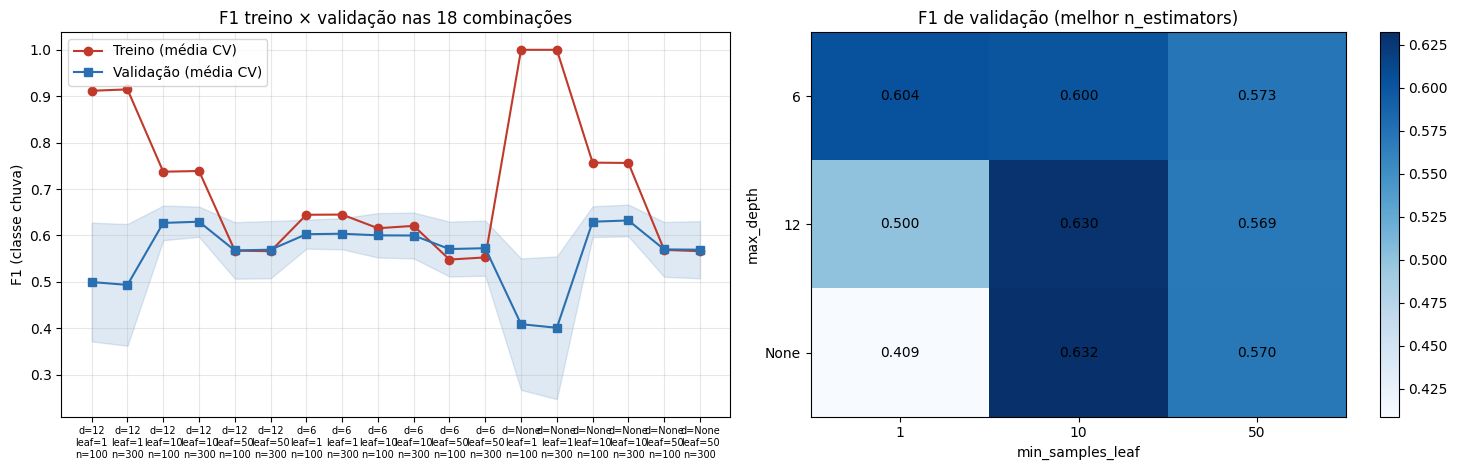

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
ordem = tabela_cv.sort_values(["max_depth", "min_samples_leaf", "n_estimators"]).reset_index(drop=True)
rotulos = [f"d={r.max_depth}\nleaf={r.min_samples_leaf}\nn={r.n_estimators}" for r in ordem.itertuples()]
x = np.arange(len(ordem))
axes[0].plot(x, ordem["F1 treino (CV)"], "o-", label="Treino (média CV)", color="#c0392b")
axes[0].plot(x, ordem["F1 validação (CV)"], "s-", label="Validação (média CV)", color="#2a6fb0")
axes[0].fill_between(x, ordem["F1 validação (CV)"] - ordem["desvio F1 val."],
                     ordem["F1 validação (CV)"] + ordem["desvio F1 val."], alpha=0.15, color="#2a6fb0")
axes[0].set_xticks(x); axes[0].set_xticklabels(rotulos, fontsize=7)
axes[0].set(title="F1 treino × validação nas 18 combinações", ylabel="F1 (classe chuva)")
axes[0].legend()

pivot = res.assign(md=res["param_max_depth"].astype(str)).pivot_table(
    index="md", columns="param_min_samples_leaf", values="mean_test_f1", aggfunc="max")
pivot = pivot.reindex(["6", "12", "None"])
im = axes[1].imshow(pivot.values, cmap="Blues", aspect="auto")
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        axes[1].text(j, i, f"{pivot.values[i, j]:.3f}", ha="center", va="center")
axes[1].set_xticks(range(pivot.shape[1])); axes[1].set_xticklabels(pivot.columns)
axes[1].set_yticks(range(pivot.shape[0])); axes[1].set_yticklabels(pivot.index)
axes[1].set(title="F1 de validação (melhor n_estimators)", xlabel="min_samples_leaf", ylabel="max_depth")
axes[1].grid(False)
plt.colorbar(im, ax=axes[1])
plt.tight_layout(); fig.savefig(FIG_DIR / "hiperparametros.png", bbox_inches="tight"); plt.show()

O gráfico da esquerda mostra a **curva de complexidade**: árvores sem limite de profundidade e com `min_samples_leaf=1` quase decoram o treino (F1 de treino próximo de 1), mas **não validam melhor** — é o sinal clássico de overfitting. Aumentar `min_samples_leaf` ou limitar `max_depth` aproxima as curvas de treino e validação.

## 6. Resultados em treino e teste

O melhor modelo da validação cruzada é retreinado em todo o treino (2023–2024) e avaliado **uma única vez** no teste (2025).

In [9]:
modelo = search.best_estimator_

def avaliar(y, pred, prob=None):
    return {
        "Acurácia": accuracy_score(y, pred),
        "Precisão (chuva)": precision_score(y, pred, zero_division=0),
        "Recall (chuva)": recall_score(y, pred, zero_division=0),
        "F1 (chuva)": f1_score(y, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y, prob) if prob is not None else np.nan,
        "PR-AUC": average_precision_score(y, prob) if prob is not None else np.nan,
    }

prob_train = modelo.predict_proba(X_train)[:, 1]
prob_test = modelo.predict_proba(X_test)[:, 1]
pred_train = modelo.predict(X_train)
pred_test = modelo.predict(X_test)

metricas = pd.DataFrame({
    "Treino": avaliar(y_train, pred_train, prob_train),
    "Teste": avaliar(y_test, pred_test, prob_test),
})
metricas["Diferença (treino − teste)"] = metricas["Treino"] - metricas["Teste"]
metricas.round(3)

,Treino,Teste,Diferença (treino − teste)
Acurácia,0.955,0.941,0.015
Precisão (chuva),0.656,0.535,0.121
Recall (chuva),0.909,0.656,0.253
F1 (chuva),0.762,0.590,0.173
ROC-AUC,0.986,0.931,0.055
PR-AUC,0.850,0.596,0.253


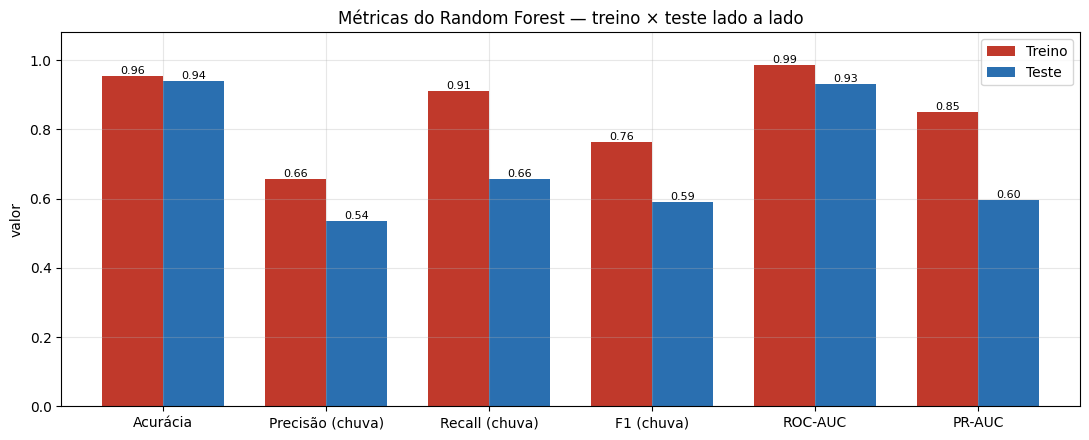

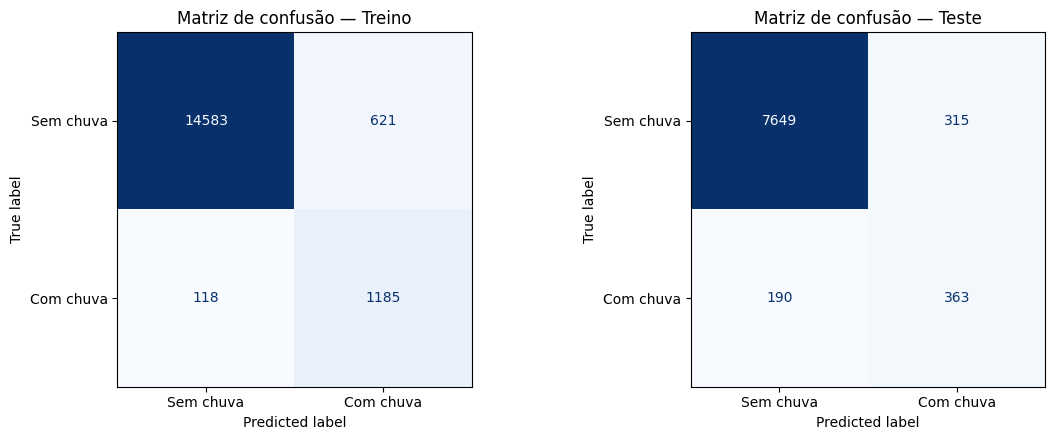

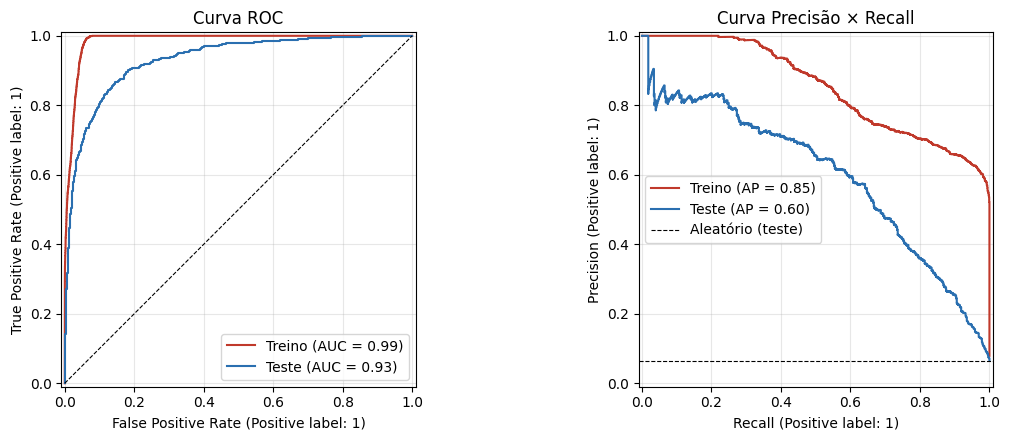

In [10]:
fig, ax = plt.subplots(figsize=(11, 4.5))
metricas[["Treino", "Teste"]].plot.bar(ax=ax, color=["#c0392b", "#2a6fb0"], width=0.75)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=8)
ax.set(title="Métricas do Random Forest — treino × teste lado a lado", ylim=(0, 1.08), ylabel="valor")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); fig.savefig(FIG_DIR / "metricas_treino_teste.png", bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (nome, y, p) in zip(axes, [("Treino", y_train, pred_train), ("Teste", y_test, pred_test)]):
    ConfusionMatrixDisplay.from_predictions(y, p, display_labels=["Sem chuva", "Com chuva"],
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"Matriz de confusão — {nome}"); ax.grid(False)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
RocCurveDisplay.from_predictions(y_train, prob_train, name="Treino", ax=axes[0], color="#c0392b")
RocCurveDisplay.from_predictions(y_test, prob_test, name="Teste", ax=axes[0], color="#2a6fb0")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8); axes[0].set_title("Curva ROC")
PrecisionRecallDisplay.from_predictions(y_train, prob_train, name="Treino", ax=axes[1], color="#c0392b")
PrecisionRecallDisplay.from_predictions(y_test, prob_test, name="Teste", ax=axes[1], color="#2a6fb0")
axes[1].axhline(y_test.mean(), ls="--", c="k", lw=0.8, label="Aleatório (teste)")
axes[1].legend(); axes[1].set_title("Curva Precisão × Recall")
plt.tight_layout(); fig.savefig(FIG_DIR / "roc_pr_treino_teste.png", bbox_inches="tight"); plt.show()

### Comparação com as referências (no mesmo teste de 2025)

In [11]:
pers_test = (X_test["precipitacao_mm"] > 0).astype(int)
nunca = np.zeros_like(y_test)
comparacao = pd.DataFrame({
    "Sempre 'não chove'": avaliar(y_test, nunca),
    "Persistência (chove agora → chove depois)": avaliar(y_test, pers_test),
    "Random Forest (teste)": avaliar(y_test, pred_test, prob_test),
}).T
display(comparacao.round(3))

print("Relatório de classificação — TESTE (2025):")
print(classification_report(y_test, pred_test, target_names=["sem chuva", "com chuva"], digits=3))

tn, fp, fn, tp = pd.crosstab(y_test, pred_test).values.ravel()
tn_p, fp_p, fn_p, tp_p = pd.crosstab(y_test, pers_test).values.ravel()
print(f"Horas de chuva no teste: {tp + fn}")
print(f"  Random Forest avisou antes: {tp} ({tp/(tp+fn):.1%}) | perdeu: {fn} | alarmes falsos: {fp}")
print(f"  Persistência avisou antes:  {tp_p} ({tp_p/(tp_p+fn_p):.1%}) | perdeu: {fn_p} | alarmes falsos: {fp_p}")

# O caso mais útil para o cidadão: a chuva COMEÇA na próxima hora (agora está seco)
inicio = (y_test == 1) & (X_test["precipitacao_mm"] == 0)
print(f"\nInícios de chuva no teste (seco agora, chove na próxima hora): {inicio.sum()} horas")
print(f"  Persistência antecipou: 0 (0.0%) - por definição ela nunca prevê o início")
print(f"  Random Forest antecipou: {pred_test[inicio.values].sum()} ({pred_test[inicio.values].mean():.1%})")
print(f"  Probabilidade média dada pelo RF nesses inícios: {prob_test[inicio.values].mean():.2f} "
      f"vs. {prob_test[((y_test == 0) & (X_test['precipitacao_mm'] == 0)).values].mean():.2f} em horas secas que seguem secas")

,Acurácia,Precisão (chuva),Recall (chuva),F1 (chuva),ROC-AUC,PR-AUC
Sempre 'não chove',0.935,0.000,0.000,0.000,NaN,NaN
Persistência (chove agora → chove depois),0.945,0.576,0.575,0.576,NaN,NaN
Random Forest (teste),0.941,0.535,0.656,0.590,0.931,0.596


Relatório de classificação — TESTE (2025):
              precision    recall  f1-score   support

   sem chuva      0.976     0.960     0.968      7964
   com chuva      0.535     0.656     0.590       553

    accuracy                          0.941      8517
   macro avg      0.756     0.808     0.779      8517
weighted avg      0.947     0.941     0.943      8517

Horas de chuva no teste: 553
  Random Forest avisou antes: 363 (65.6%) | perdeu: 190 | alarmes falsos: 315
  Persistência avisou antes:  318 (57.5%) | perdeu: 235 | alarmes falsos: 234

Inícios de chuva no teste (seco agora, chove na próxima hora): 235 horas
  Persistência antecipou: 0 (0.0%) - por definição ela nunca prevê o início
  Random Forest antecipou: 46 (19.6%)
  Probabilidade média dada pelo RF nesses inícios: 0.33 vs. 0.09 em horas secas que seguem secas


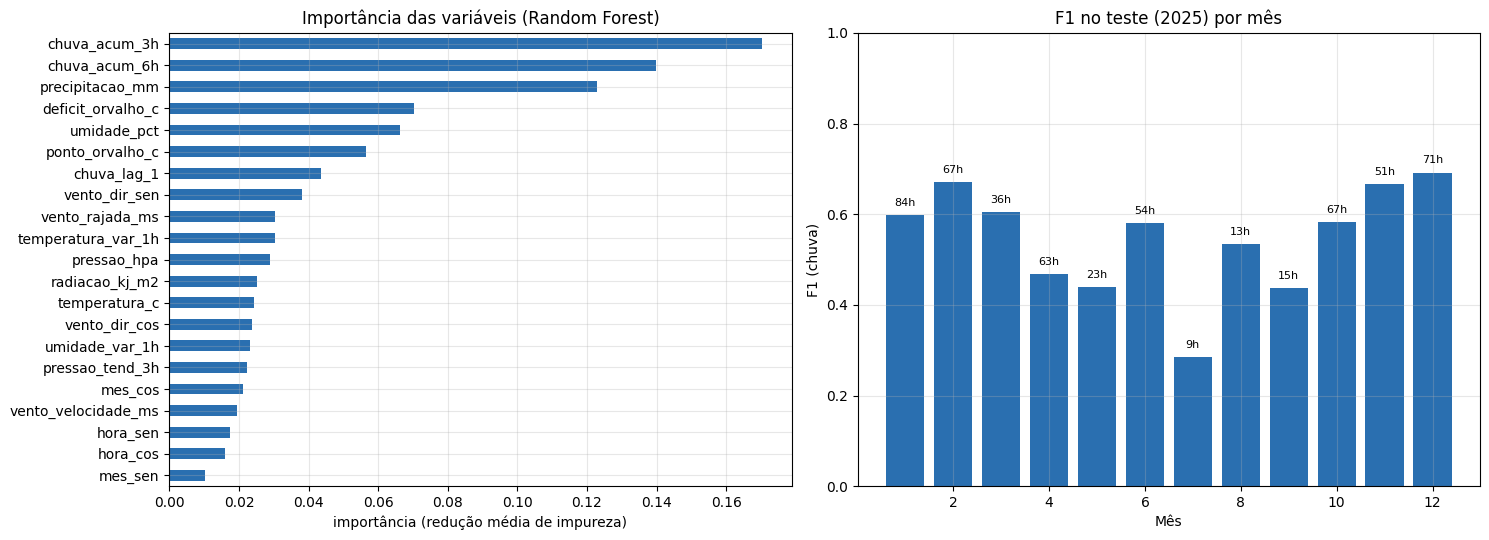

Números acima das barras = horas de chuva no mês (meses secos têm poucos exemplos).


In [12]:
imp = pd.Series(modelo.feature_importances_, index=FEATURES).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
imp.plot.barh(ax=axes[0], color="#2a6fb0")
axes[0].set(title="Importância das variáveis (Random Forest)", xlabel="importância (redução média de impureza)")

f1_mes = pd.DataFrame({"y": y_test, "p": pred_test}).groupby(y_test.index.month).apply(
    lambda g: f1_score(g["y"], g["p"], zero_division=0))
chuva_mes = y_test.groupby(y_test.index.month).sum()
axes[1].bar(f1_mes.index, f1_mes.values, color="#2a6fb0")
axes[1].set(title="F1 no teste (2025) por mês", xlabel="Mês", ylabel="F1 (chuva)", ylim=(0, 1))
for m in f1_mes.index:
    axes[1].text(m, f1_mes[m] + 0.02, f"{chuva_mes[m]}h", ha="center", fontsize=8)
plt.tight_layout(); plt.show()
print("Números acima das barras = horas de chuva no mês (meses secos têm poucos exemplos).")

### Exemplo de uso: como o aviso chegaria ao cidadão

In [13]:
def aviso(prob):
    if prob >= 0.7: return "ALTA chance de chuva na próxima hora - leve guarda-chuva / evite áreas de alagamento"
    if prob >= 0.4: return "Chance moderada de chuva na próxima hora"
    return "Baixa chance de chuva na próxima hora"

dia_chuvoso = y_test[y_test == 1].index[len(y_test[y_test == 1]) // 2].normalize()
janela = teste.loc[dia_chuvoso + pd.Timedelta(hours=12): dia_chuvoso + pd.Timedelta(hours=21)]
exemplo = pd.DataFrame({
    "chuva agora (mm)": janela["precipitacao_mm"],
    "umidade (%)": janela["umidade_pct"],
    "prob. chuva próx. hora": modelo.predict_proba(janela[FEATURES])[:, 1].round(2),
    "choveu na próx. hora?": janela[TARGET].map({0: "não", 1: "sim"}),
})
exemplo["aviso"] = exemplo["prob. chuva próx. hora"].map(aviso)
exemplo

,chuva agora (mm),umidade (%),prob. chuva próx. hora,choveu na próx. hora?,aviso
data_hora,,,,,
2025-06-05 12:00:00-03:00,0.0,54.0,0.02,não,Baixa chance de chuva na próxima hora
2025-06-05 13:00:00-03:00,0.0,54.0,0.07,não,Baixa chance de chuva na próxima hora
2025-06-05 14:00:00-03:00,0.0,55.0,0.11,não,Baixa chance de chuva na próxima hora
2025-06-05 15:00:00-03:00,0.0,76.0,0.18,sim,Baixa chance de chuva na próxima hora
2025-06-05 16:00:00-03:00,12.2,90.0,0.97,sim,ALTA chance de chuva na próxima hora - leve gu...
2025-06-05 17:00:00-03:00,1.0,92.0,0.98,sim,ALTA chance de chuva na próxima hora - leve gu...
2025-06-05 18:00:00-03:00,6.8,92.0,0.98,não,ALTA chance de chuva na próxima hora - leve gu...
2025-06-05 19:00:00-03:00,0.0,92.0,0.62,sim,Chance moderada de chuva na próxima hora
2025-06-05 20:00:00-03:00,3.2,92.0,0.91,não,ALTA chance de chuva na próxima hora - leve gu...


## 7. Discussão: overfitting

Melhor combinação na validação cruzada: `n_estimators=300`, `max_depth=None`, `min_samples_leaf=10`.

| Métrica | Treino | Teste (2025) | Diferença |
|---|---|---|---|
| Acurácia | 0,955 | 0,941 | 0,015 |
| Precisão (chuva) | 0,656 | 0,535 | 0,121 |
| Recall (chuva) | 0,909 | 0,656 | 0,253 |
| F1 (chuva) | 0,762 | 0,590 | 0,173 |
| ROC-AUC | 0,986 | 0,931 | 0,055 |
| PR-AUC | 0,850 | 0,596 | 0,253 |

- **Há overfitting moderado:** o modelo vai melhor no treino que no teste (F1 0,76 → 0,59; recall 0,91 → 0,66). As árvores memorizam parte das horas de chuva de 2023–2024.
- **A grade de hiperparâmetros mostra o fenômeno com clareza:** árvores livres com `min_samples_leaf=1` atingem F1 = 1,00 no treino e só 0,40 na validação (gap ≈ 0,60). Exigir ao menos 10 amostras por folha reduziu o gap para ≈ 0,12 e deu o **melhor F1 de validação (0,632)**. Com `min_samples_leaf=50` o gap some, mas o modelo fica simples demais (*underfitting*, F1 ≈ 0,57).
- **A validação temporal foi uma boa estimativa:** F1 de teste (0,590) ficou próximo do F1 médio de validação (0,632 ± 0,034); ROC-AUC de teste (0,931) ≈ validação (0,921). Ou seja, o resultado em um ano nunca visto é coerente com o esperado.
- **Parte da queda vem do próprio ano de 2025**, mais seco (6,5 % de horas com chuva contra 7,9 % no treino) — o F1 mensal mostra desempenho pior nos meses secos (jul: 9 h de chuva), onde há poucos exemplos.
- **Acurácia engana:** “nunca chove” já acerta 93,5 %; por isso a análise usa F1, recall, precisão e PR-AUC da classe chuva.

## 8. Conclusão para o cidadão

- **O que o modelo responde:** com as medições oficiais do INMET da hora atual, ele estima a probabilidade de chover na próxima hora no entorno do Mirante de Santana (zona norte/centro de SP).
- **O que isso significa na prática:** em 2025 houve 553 horas de chuva; o modelo avisou com 1 hora de antecedência em **363 delas (65,6 %)**, contra 318 (57,5 %) da regra intuitiva “se está chovendo, vai continuar chovendo”. A grande diferença está no **início da chuva**: em 235 horas a chuva começou com o tempo ainda seco — a regra de persistência nunca avisa esses casos, e o modelo antecipou **46 (19,6 %)**, atribuindo em média probabilidade de 0,33 a esses inícios contra 0,09 em horas que continuaram secas.
- **Custo:** de cada 100 alertas “vai chover”, cerca de 54 se confirmam (precisão 0,535) — há alarmes falsos. Para um aviso de “leve o guarda-chuva / saia mais cedo”, um alarme falso custa pouco e uma chuva perdida custa mais, por isso privilegiamos recall.
- **Como usar:** como aviso em app/painel (ex.: “alta chance de chuva na próxima hora”), útil para decidir sair agora, pegar transporte público mais cedo ou evitar pontos de alagamento.
- **Limites:** uma única estação representa a vizinhança, não a cidade toda (chuvas de verão em SP são muito localizadas); ainda há alarmes falsos e chuvas perdidas; o modelo não prevê volume de chuva nem alagamento. Deve **complementar** os alertas da Defesa Civil/CGE, não substituí-los.
- **Próximos passos:** usar várias estações do INMET/CGE para cobrir mais bairros, prever horizontes de 2–3 h e calibrar o limiar de alerta junto com a Defesa Civil.